<a href="https://colab.research.google.com/github/1322vishav/Image-Processing/blob/main/Assignment7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import numpy as np
import matplotlib.pyplot as plt

IMG_PATH = '/content/drive/MyDrive/image.jpg'

gray_u8 = cv2.imread(IMG_PATH, cv2.IMREAD_GRAYSCALE)
if gray_u8 is None:
    raise FileNotFoundError(f"Could not read {IMG_PATH}")

gray = gray_u8.astype(np.float64)

def to_u8(a):
    return np.clip(a, 0, 255).astype(np.uint8)

print("Image shape:", gray.shape)

Mounted at /content/drive
Image shape: (720, 1280)


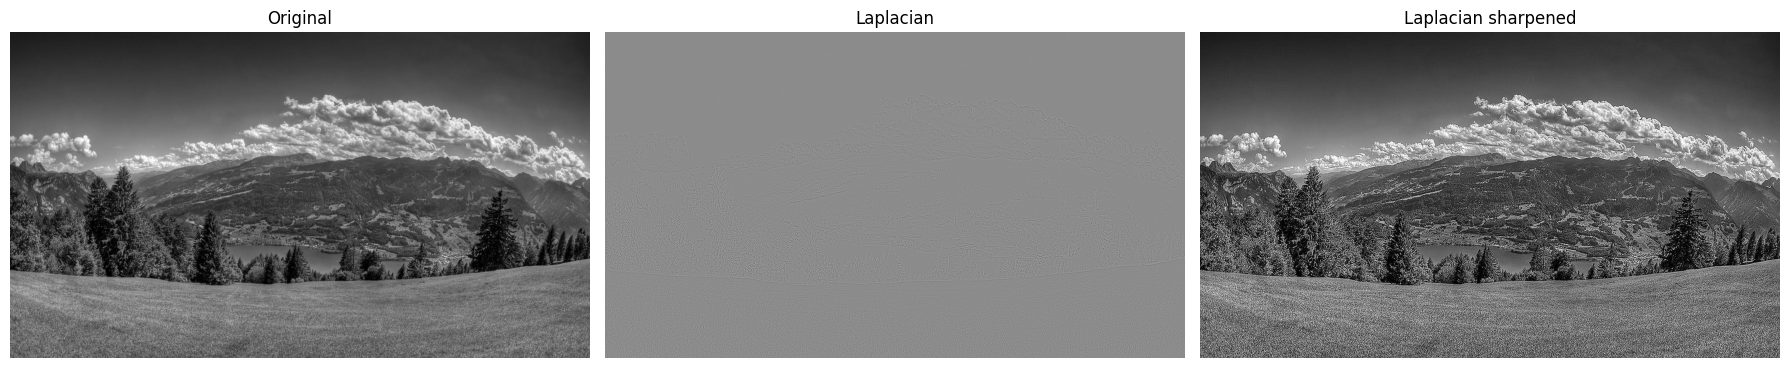

In [2]:
kernel = np.array([[0, 1, 0],
                   [1, -4, 1],
                   [0, 1, 0]], dtype=np.float64)

lap = cv2.filter2D(gray, -1, kernel, borderType=cv2.BORDER_REFLECT_101)
lap_sharp = to_u8(gray - lap)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(gray_u8, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('Original')
ax[1].imshow(lap, cmap='gray')
ax[1].set_title('Laplacian')
ax[2].imshow(lap_sharp, cmap='gray', vmin=0, vmax=255)
ax[2].set_title('Laplacian sharpened')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

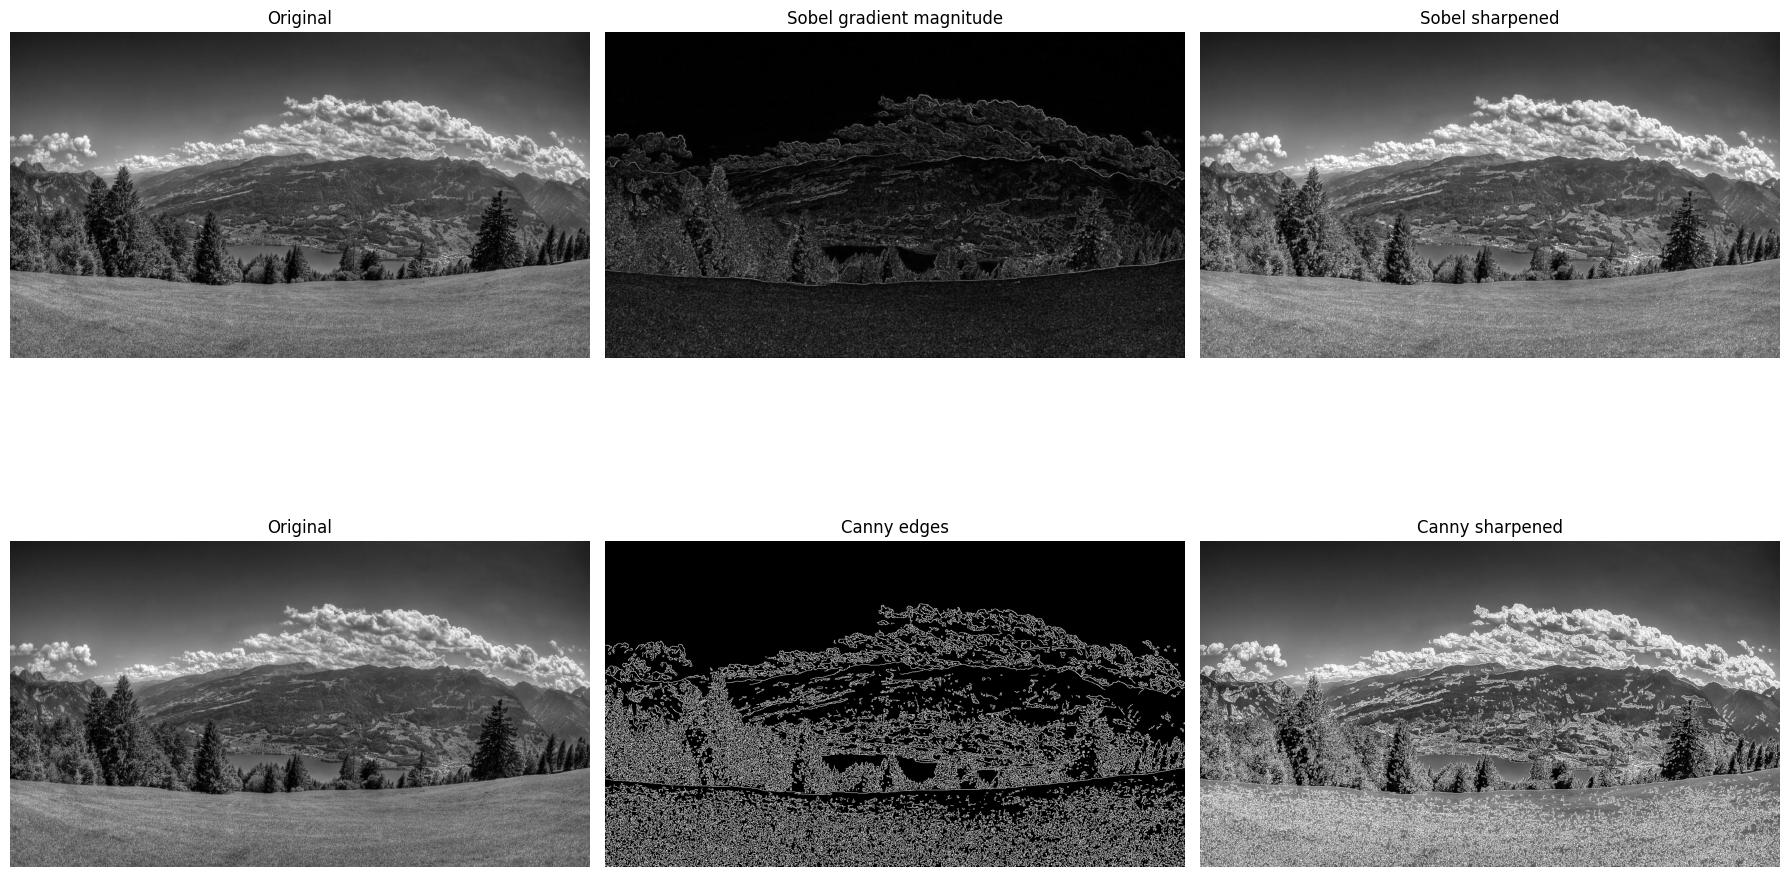

In [3]:
alpha = 0.5

gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
mag = np.abs(gx) + np.abs(gy)
mag = mag / mag.max() * 255
sobel_sharp = to_u8(gray + alpha * mag)

edges = cv2.Canny(gray_u8, 100, 200)
canny_sharp = to_u8(gray + alpha * edges)

fig, ax = plt.subplots(2, 3, figsize=(18, 12))
ax[0, 0].imshow(gray_u8, cmap='gray', vmin=0, vmax=255)
ax[0, 0].set_title('Original')
ax[0, 1].imshow(mag, cmap='gray')
ax[0, 1].set_title('Sobel gradient magnitude')
ax[0, 2].imshow(sobel_sharp, cmap='gray', vmin=0, vmax=255)
ax[0, 2].set_title('Sobel sharpened')
ax[1, 0].imshow(gray_u8, cmap='gray', vmin=0, vmax=255)
ax[1, 0].set_title('Original')
ax[1, 1].imshow(edges, cmap='gray')
ax[1, 1].set_title('Canny edges')
ax[1, 2].imshow(canny_sharp, cmap='gray', vmin=0, vmax=255)
ax[1, 2].set_title('Canny sharpened')
for a in ax.ravel():
    a.axis('off')
plt.tight_layout()
plt.show()

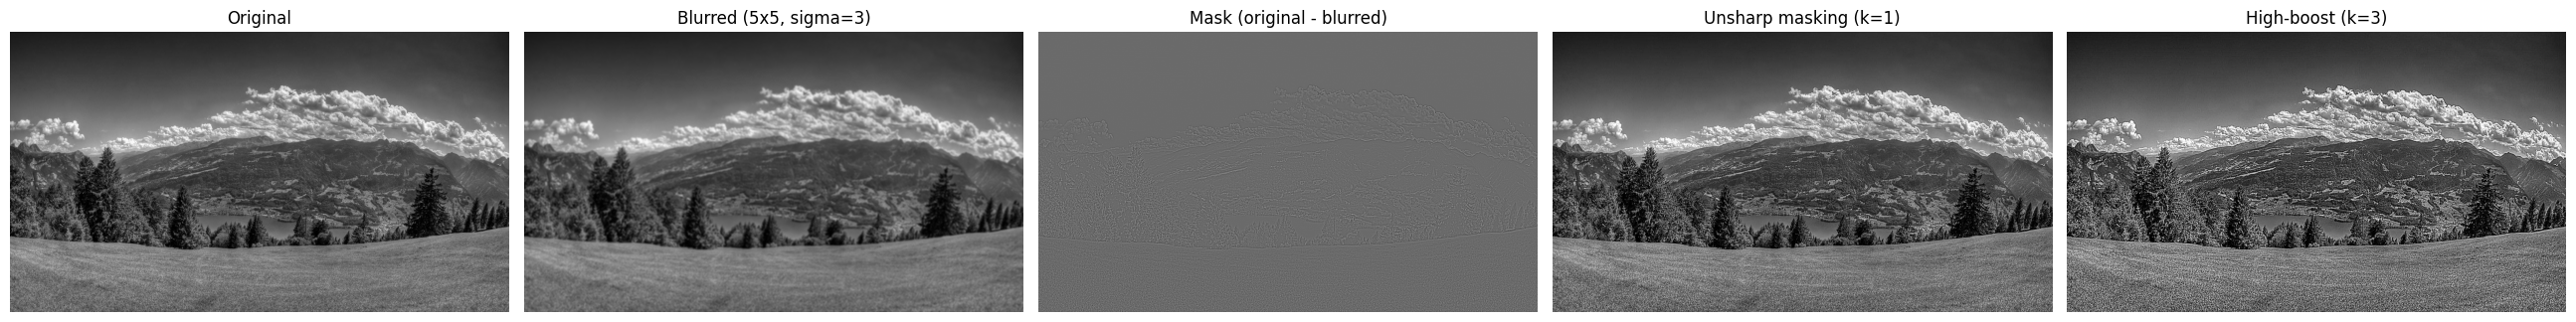

In [4]:
k_boost = 3

blur = cv2.GaussianBlur(gray, (5, 5), sigmaX=3)
mask = gray - blur
unsharp = to_u8(gray + mask)
highboost = to_u8(gray + k_boost * mask)

fig, ax = plt.subplots(1, 5, figsize=(26, 6))
ax[0].imshow(gray_u8, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('Original')
ax[1].imshow(blur, cmap='gray', vmin=0, vmax=255)
ax[1].set_title('Blurred (5x5, sigma=3)')
ax[2].imshow(mask, cmap='gray')
ax[2].set_title('Mask (original - blurred)')
ax[3].imshow(unsharp, cmap='gray', vmin=0, vmax=255)
ax[3].set_title('Unsharp masking (k=1)')
ax[4].imshow(highboost, cmap='gray', vmin=0, vmax=255)
ax[4].set_title(f'High-boost (k={k_boost})')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

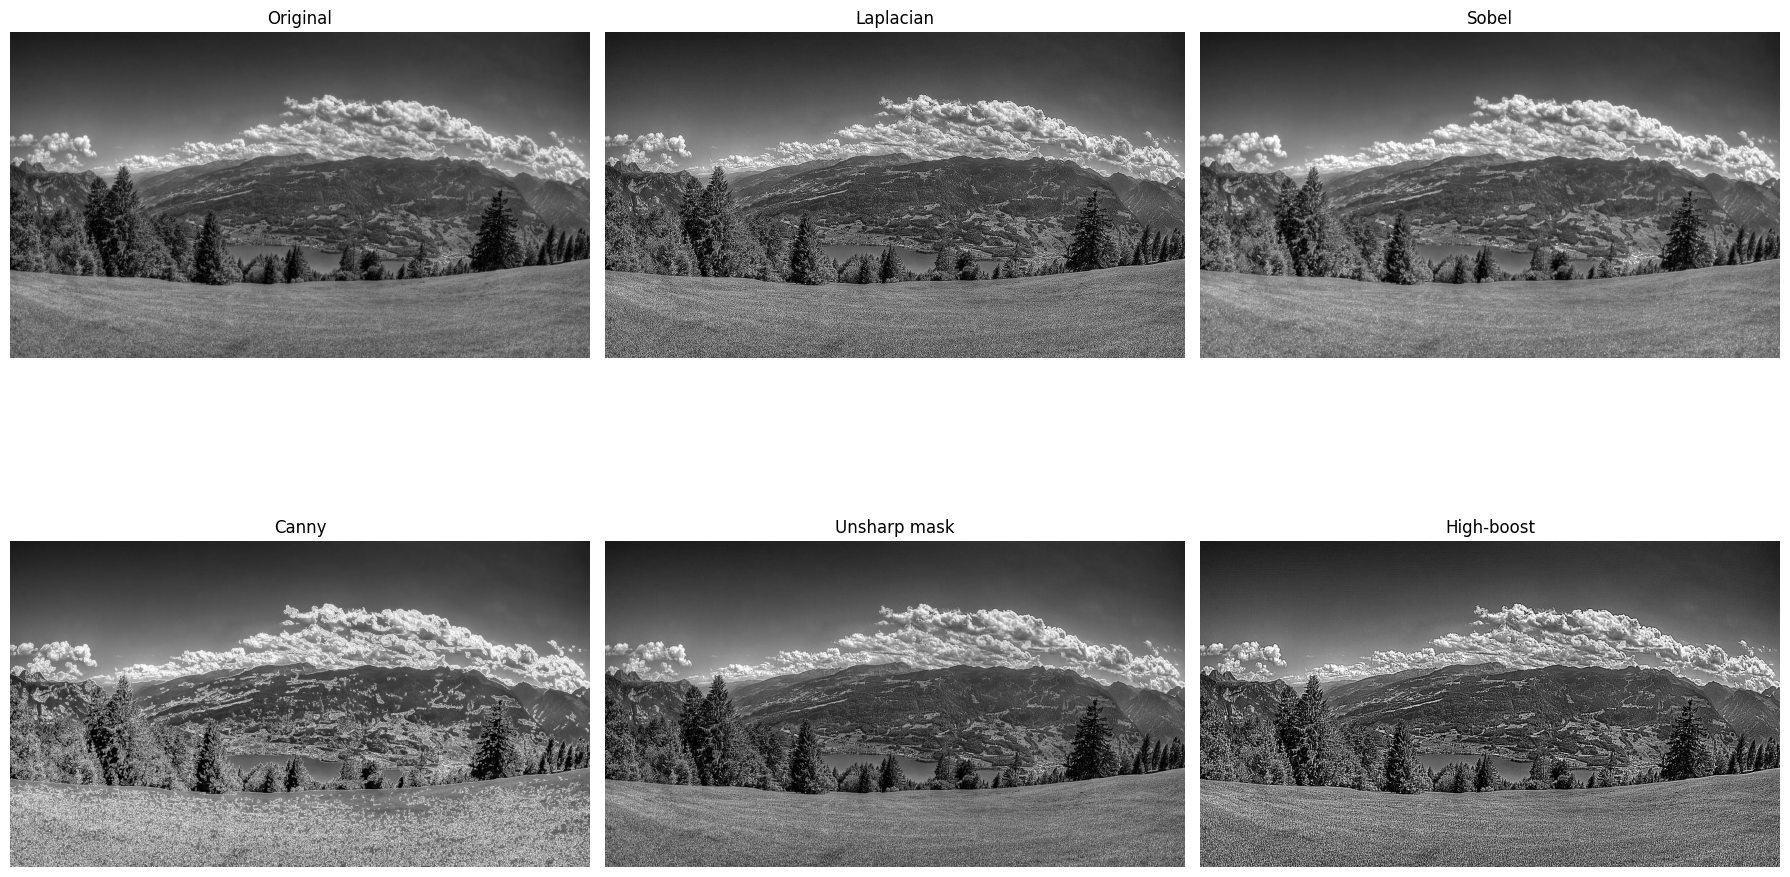

In [5]:
results = [(gray_u8, 'Original'),
           (lap_sharp, 'Laplacian'),
           (sobel_sharp, 'Sobel'),
           (canny_sharp, 'Canny'),
           (unsharp, 'Unsharp mask'),
           (highboost, 'High-boost')]

fig, ax = plt.subplots(2, 3, figsize=(18, 12))
for a, (im, t) in zip(ax.ravel(), results):
    a.imshow(im, cmap='gray', vmin=0, vmax=255)
    a.set_title(t)
    a.axis('off')
plt.tight_layout()
plt.show()